## VISUALIZE

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import scipy
import pandas as pd
from matplotlib.colors import Normalize



In [2]:
filename = 'schwarz_image_data_20M_2.txt'
data = pd.read_csv(filename, delimiter=',', header=None)

#r
print(np.min(data.iloc[:,3]), np.max(data.iloc[:,3]), np.mean(data.iloc[:,3]))
#theta
print(np.min(data.iloc[:,4]), np.max(data.iloc[:,4]), np.mean(data.iloc[:,4]))
#size
print(np.min(data.iloc[:,5]), np.max(data.iloc[:,5]), np.mean(data.iloc[:,5]))
#hamiltonian
print(np.min(data.iloc[:,6]), np.max(data.iloc[:,6]))
#carter constant
print(np.min(data.iloc[:,7]), np.max(data.iloc[:,7]))
#redshift factor
print(np.min(data.iloc[:,8]), np.max(data.iloc[:,8]))

2.0 20.0 17.1483284953
-0.692126 3.13507 1.5787686037388395
535 6216 3223.592404
3.06716e-16 0.00464453
0.0 0.220568
0.0 1.41167


In [3]:
len(data.iloc[:,0])

1000000

In [4]:



r = data.iloc[:,3]
colour_bool = data.iloc[:,2]
redshift = data.iloc[:, 8]
'''
# Define constants for the temperature profile
T_0 = 1e6  # Temperature at ISCO in Kelvin
r_ISCO = 6.0  # ISCO radius (in units consistent with your data)
n = 0.75  # Power-law index for temperature falloff

# Calculate temperature for each photon
T = np.zeros(len(colour_bool))
for i in range(0, len(colour_bool)):
    if colour_bool[i]==1:
        T[i] = 0
    else:
        T[i] = T_0 * (r[i] / r_ISCO) ** -n
'''

# Calculate temperature for each photon
I_obs = redshift**3./r**3.
T_obs = redshift/r**(3./4.)

    

'''
# Custom normalization to ensure T=0 maps to black
norm = Normalize(vmin=0, vmax=np.max(T))

# Scatter plot with custom colormap
scatter = ax.scatter(data[0], data[1], c=T, cmap='inferno', norm=norm, s=0.0025)


#scatter = ax.scatter(data[0], data[1], c=T, cmap='plasma', s=7)
# Add colorbar for temperature
#colorbar = plt.colorbar(scatter, ax=ax)
#colorbar.set_label(r'Temperature (K)', rotation=270, labelpad=15)


#ax.set_xaxisoff()
#ax.set_yticks([])
#plt.xlabel(r'$x=-rsin\beta$')
#plt.ylabel(r'$y=rsin \alpha$')
#plt.show()'''

"\n# Custom normalization to ensure T=0 maps to black\nnorm = Normalize(vmin=0, vmax=np.max(T))\n\n# Scatter plot with custom colormap\nscatter = ax.scatter(data[0], data[1], c=T, cmap='inferno', norm=norm, s=0.0025)\n\n\n#scatter = ax.scatter(data[0], data[1], c=T, cmap='plasma', s=7)\n# Add colorbar for temperature\n#colorbar = plt.colorbar(scatter, ax=ax)\n#colorbar.set_label(r'Temperature (K)', rotation=270, labelpad=15)\n\n\n#ax.set_xaxisoff()\n#ax.set_yticks([])\n#plt.xlabel(r'$x=-rsin\x08eta$')\n#plt.ylabel(r'$y=rsin \x07lpha$')\n#plt.show()"

In [5]:


xi = np.linspace(data[0].min(), data[0].max(), 500)
yi = np.linspace(data[1].min(), data[1].max(), 500)
Xi, Yi = np.meshgrid(xi, yi)

Zi = scipy.interpolate.griddata((data[0], data[1]), I_obs, (Xi, Yi), method='linear')



In [6]:
Zi_temp = scipy.interpolate.griddata((data[0], data[1]), T_obs, (Xi, Yi), method='linear')

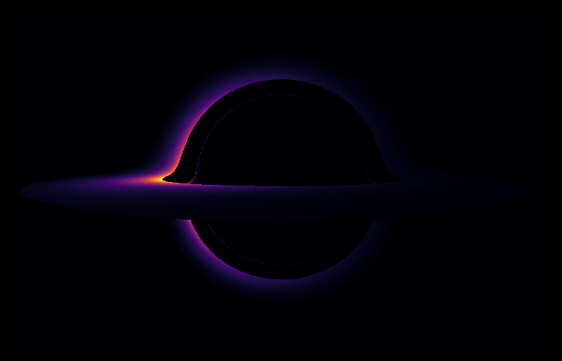

In [6]:
#Image
fig, ax = plt.subplots(figsize=(7, 7))

plt.imshow(Zi, extent=[xi.min(), xi.max(), yi.min(), yi.max()], origin='lower', cmap='inferno')
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# Remove axes completely
ax.axis('off')
plt.show()

## Hamiltonian

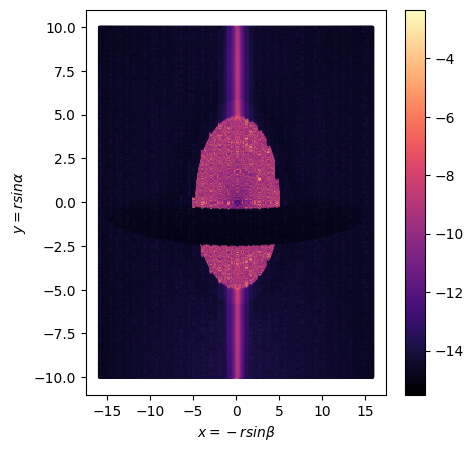

In [7]:
# Hamiltonian
fig, ax = plt.subplots(figsize=(5, 5), gridspec_kw={'left': 0.148})

# Scatter plot with color encoding for Hamiltonian
scatter = ax.scatter(data[0], data[1], c=np.log10(data[6]), cmap='magma', s=1)

# Add a colorbar
colorbar = plt.colorbar(scatter, ax=ax)

#data.plot.scatter(x=0, y=1, c=np.log10(data.iloc[:,6]), cmap ='magma', s=7, figsize=(5,5), ax=ax)
#ax.scatter(data[0], data[1], c=np.log10(data[6]), cmap='magma', s=7)

plt.xlabel(r'$x=-rsin\beta$')
plt.ylabel(r'$y=rsin \alpha$')

plt.show()

## Carter Constant

c:\Users\Ayush Roy\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\arraylike.py:396: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


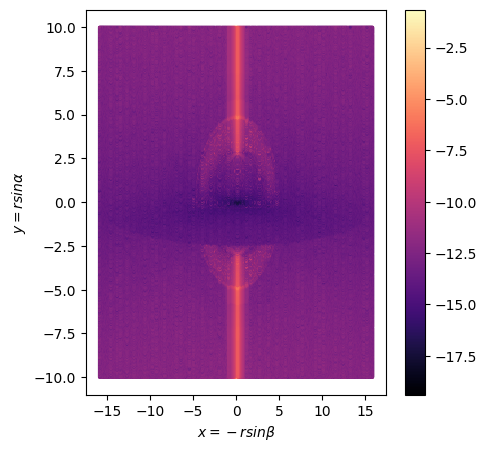

In [8]:
#Carter Constant
fig, ax = plt.subplots(figsize=(5, 5), gridspec_kw={'left': 0.148})

# Scatter plot with color encoding for Hamiltonian
scatter = ax.scatter(data[0], data[1], c=np.log10(data[7]), cmap='magma', s=1)

# Add a colorbar
colorbar = plt.colorbar(scatter, ax=ax)

#data.plot.scatter(x=0, y=1, c=np.log10(data.iloc[:,7]), cmap ='magma', s=7, figsize=(5,5), ax=ax)
#ax.scatter(data[0], data[1], c=np.log10(data[7]), cmap='magma', s=7)

plt.xlabel(r'$x=-rsin\beta$')
plt.ylabel(r'$y=rsin \alpha$')

plt.show()